# Notebook 3 — Modelagem

**TCC — Desenvolvimento de modelo preditivo interpretável de machine learning para
identificação de alunos em risco de evasão no ensino superior**
Curso de Sistemas de Informação — UEMG

---

## Objetivo

Fase 4 do CRISP-DM (*Modeling*): treinar, otimizar e comparar três algoritmos, escolhendo um
para a análise de interpretabilidade do Notebook 4.

| Modelo | Papel no trabalho |
|---|---|
| **Regressão Logística** | Linha de base — modelo linear, interpretável por construção |
| **Random Forest** | *Ensemble* de árvores por *bagging* |
| **XGBoost** | *Ensemble* por *gradient boosting*, estado da arte em dados tabulares |

A progressão é intencional: se um modelo complexo não superar a linha de base linear de forma
relevante, a escolha correta é o modelo simples. Complexidade precisa ser justificada por ganho
mensurável, e a Regressão Logística existe aqui exatamente para impor esse ônus da prova.

## Critério de decisão

O modelo vencedor será escolhido por **F1-score da classe `Dropout`**, com o **recall** dessa classe
como critério de desempate. A acurácia é reportada apenas para constar — ela é enganosa neste
problema, como a seção 3 demonstra numericamente.

## 1. Configuração e carga dos artefatos

In [1]:
# --- Bibliotecas -------------------------------------------------------------
import os
import sys
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, classification_report, confusion_matrix,
    roc_curve, precision_recall_curve, balanced_accuracy_score,
    matthews_corrcoef,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as PipelineImb

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)

DIR_DADOS = "dados"
DIR_FIGURAS = "figuras"
DIR_MODELOS = "modelos"
for _d in (DIR_DADOS, DIR_FIGURAS, DIR_MODELOS):
    os.makedirs(_d, exist_ok=True)

if "src" not in sys.path:
    sys.path.insert(0, "src")
from data_loader import rotulo   # noqa: E402

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11,
})

CORES_MODELO = {
    "Regressão Logística": "#2c7fb8",
    "Random Forest": "#238b45",
    "XGBoost": "#d94801",
}

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

print(f"Ambiente pronto | SEED = {SEED} | CPUs disponíveis: {os.cpu_count()}")

Ambiente pronto | SEED = 42 | CPUs disponíveis: 32


In [2]:
# --- Artefatos do Notebook 2 -------------------------------------------------
# Treino SEM SMOTE: base da validação cruzada (ver justificativa na seção 2)
X_treino = pd.read_csv(os.path.join(DIR_DADOS, "X_train_sem_smote.csv"))
y_treino = pd.read_csv(os.path.join(DIR_DADOS, "y_train_sem_smote.csv"))["target"]

# Treino JÁ balanceado: usado apenas para conferir a equivalência (seção 2)
X_treino_bal = pd.read_csv(os.path.join(DIR_DADOS, "X_train.csv"))
y_treino_bal = pd.read_csv(os.path.join(DIR_DADOS, "y_train.csv"))["target"]

# Teste: intocado desde a separação
X_teste = pd.read_csv(os.path.join(DIR_DADOS, "X_test.csv"))
y_teste = pd.read_csv(os.path.join(DIR_DADOS, "y_test.csv"))["target"]

with open(os.path.join(DIR_DADOS, "metadados.json"), encoding="utf-8") as fh:
    META = json.load(fh)

CLASSES = {int(k): v for k, v in META["classes"].items()}
NOMES_CLASSES = [CLASSES[i] for i in sorted(CLASSES)]

print(f"Formulação        : {META['formulacao']}")
print(f"Classe positiva   : {META['classe_positiva']} (código 1)")
print(f"Features          : {META['n_features']}")
print()
print(f"Treino (natural)  : {X_treino.shape}  -> {y_treino.mean():.1%} de evasão")
print(f"Treino (SMOTE)    : {X_treino_bal.shape}  -> {y_treino_bal.mean():.1%} de evasão")
print(f"Teste  (natural)  : {X_teste.shape}  -> {y_teste.mean():.1%} de evasão")

Formulação        : binaria
Classe positiva   : Dropout (código 1)
Features          : 105

Treino (natural)  : (2904, 105)  -> 39.2% de evasão
Treino (SMOTE)    : (3534, 105)  -> 50.0% de evasão
Teste  (natural)  : (726, 105)  -> 39.1% de evasão


## 2. Onde o SMOTE entra na validação cruzada

Aqui existe uma armadilha que merece atenção, porque é sutil e muito comum.

O Notebook 2 gerou um conjunto de treino balanceado (3.534 registros). O caminho intuitivo seria
rodar a validação cruzada diretamente sobre ele — e estaria **errado**. Na validação cruzada, o
treino é repartido em 5 dobras; a cada rodada, 4 servem para treinar e 1 para validar. Se o SMOTE
já foi aplicado ao conjunto inteiro, pontos sintéticos interpolados a partir de um aluno da dobra de
validação estarão presentes nas dobras de treino. O modelo então valida contra vizinhos dos próprios
registros que viu — e a métrica de validação sai inflada.

É o mesmo raciocínio que justificou aplicar SMOTE só no treino no Notebook 2, agora **um nível mais
abaixo**: dentro do treino, cada dobra precisa ser tratada como um teste em miniatura.

### Solução: SMOTE dentro do *pipeline*

Usa-se `imblearn.pipeline.Pipeline`, que difere do pipeline do scikit-learn em um ponto decisivo:
etapas de reamostragem são aplicadas **apenas no `fit`**, nunca no `predict`. Assim, em cada dobra:

```
dobras de treino  ->  SMOTE aplicado  ->  modelo treinado
dobra de validação ->  intocada       ->  modelo avaliado
```

A busca de hiperparâmetros também roda sobre esse pipeline, de modo que **nenhum hiperparâmetro é
escolhido com base em dados contaminados**. É por isso que o Notebook 2 salvou as duas versões do
treino: a natural alimenta a validação cruzada, e a balanceada serve para verificar a equivalência
abaixo.

In [3]:
# --- Verificação: o pipeline reproduz exatamente o SMOTE do Notebook 2? ------
_smote_conferencia = SMOTE(random_state=SEED, k_neighbors=5)
_X_ref, _y_ref = _smote_conferencia.fit_resample(X_treino, y_treino)

iguais_X = np.allclose(np.sort(_X_ref.to_numpy(), axis=0),
                       np.sort(X_treino_bal.to_numpy(), axis=0), atol=1e-9)
iguais_y = sorted(_y_ref) == sorted(y_treino_bal)

print(f"SMOTE do pipeline == SMOTE salvo no Notebook 2 : {iguais_X and iguais_y}")
print(f"   {len(y_treino)} registros -> {len(_y_ref)} (mesma semente, mesmo resultado)")
print()
print("Consequência: treinar o pipeline no conjunto natural completo produz o MESMO")
print("modelo que treinar direto no conjunto balanceado. A diferença aparece só na")
print("validação cruzada — e é exatamente ali que ela precisa aparecer.")

del _smote_conferencia, _X_ref, _y_ref

SMOTE do pipeline == SMOTE salvo no Notebook 2 : True
   2904 registros -> 3534 (mesma semente, mesmo resultado)

Consequência: treinar o pipeline no conjunto natural completo produz o MESMO
modelo que treinar direto no conjunto balanceado. A diferença aparece só na
validação cruzada — e é exatamente ali que ela precisa aparecer.


In [4]:
# --- Protocolo de validação compartilhado por todos os modelos ---------------
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Métricas coletadas na validação cruzada. Todas referentes à classe positiva
# (Dropout = 1), exceto acurácia e AUC, que são globais por definição.
METRICAS_CV = {
    "acuracia": "accuracy",
    "precisao": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

# Métrica de referência para escolher hiperparâmetros e o modelo final.
METRICA_ALVO = "f1"


def construir_pipeline(modelo):
    """Empacota o modelo com o SMOTE, garantindo reamostragem por dobra."""
    return PipelineImb([
        ("smote", SMOTE(random_state=SEED, k_neighbors=5)),
        ("modelo", modelo),
    ])


print(f"Validação cruzada : StratifiedKFold(5), shuffle=True, seed={SEED}")
print(f"Métrica de decisão: {METRICA_ALVO} da classe {META['classe_positiva']}")
print(f"Registros por dobra: ~{len(X_treino) // 5} para validar, ~{len(X_treino) - len(X_treino) // 5} para treinar")

Validação cruzada : StratifiedKFold(5), shuffle=True, seed=42
Métrica de decisão: f1 da classe Dropout
Registros por dobra: ~580 para validar, ~2324 para treinar


## 3. Por que a acurácia não serve aqui

Antes de treinar qualquer modelo, vale estabelecer o piso. Um classificador que ignore
completamente os dados e responda sempre "Graduate" obtém a acurácia abaixo — sem identificar
**um único** aluno em risco.

In [5]:
# --- Classificadores triviais como referência --------------------------------
referencias = []
for nome, predicao in [
    ("Sempre 'Graduate'", np.zeros(len(y_teste), dtype=int)),
    ("Sempre 'Dropout'", np.ones(len(y_teste), dtype=int)),
    ("Aleatório (50/50)", np.random.RandomState(SEED).randint(0, 2, len(y_teste))),
]:
    referencias.append({
        "estratégia": nome,
        "acurácia": accuracy_score(y_teste, predicao),
        "precisão (Dropout)": precision_score(y_teste, predicao, zero_division=0),
        "recall (Dropout)": recall_score(y_teste, predicao, zero_division=0),
        "F1 (Dropout)": f1_score(y_teste, predicao, zero_division=0),
    })

display(pd.DataFrame(referencias).set_index("estratégia").round(3))

print(f"O piso trivial de acurácia é {1 - y_teste.mean():.1%} — o percentual de concluintes no teste.")
print("Qualquer modelo precisa ser julgado CONTRA esse piso, não contra zero.")
print()
print("Note que a estratégia 'Sempre Graduate' tem acurácia alta e recall ZERO:")
print("ela seria inútil na prática e a acurácia não denunciaria isso. É esse")
print("descolamento que justifica adotar F1 e recall da classe Dropout.")

,acurácia,precisão (Dropout),recall (Dropout),F1 (Dropout)
estratégia,,,,
Sempre 'Graduate',0.609,0.000,0.000,0.000
Sempre 'Dropout',0.391,0.391,1.000,0.562
Aleatório (50/50),0.493,0.390,0.525,0.447


O piso trivial de acurácia é 60.9% — o percentual de concluintes no teste.
Qualquer modelo precisa ser julgado CONTRA esse piso, não contra zero.

Note que a estratégia 'Sempre Graduate' tem acurácia alta e recall ZERO:
ela seria inútil na prática e a acurácia não denunciaria isso. É esse
descolamento que justifica adotar F1 e recall da classe Dropout.


In [6]:
# --- Função de avaliação usada por todos os modelos --------------------------
resultados = {}      # nome -> dicionário de métricas
modelos_treinados = {}


def resumo_cv(cv_resultado):
    """Extrai {métrica: (média, desvio)} da saída de `cross_validate`."""
    return {chave: (cv_resultado[f"test_{chave}"].mean(),
                    cv_resultado[f"test_{chave}"].std())
            for chave in METRICAS_CV}


def resumo_busca(busca):
    """Extrai {métrica: (média, desvio)} da melhor configuração de um GridSearchCV."""
    i = busca.best_index_
    return {chave: (busca.cv_results_[f"mean_test_{chave}"][i],
                    busca.cv_results_[f"std_test_{chave}"][i])
            for chave in METRICAS_CV}


def avaliar_modelo(nome, pipeline, cv_resumo=None, verbose=True):
    """Treina no conjunto de treino completo, avalia no teste e registra tudo.

    O SMOTE está dentro do `pipeline`, portanto é aplicado apenas ao treino,
    tanto aqui quanto em cada dobra da validação cruzada.

    `cv_resumo` é o dicionário {métrica: (média, desvio)} da validação cruzada,
    produzido por `resumo_cv` ou `resumo_busca`.
    """
    inicio = time.time()
    pipeline.fit(X_treino, y_treino)
    tempo = time.time() - inicio

    y_pred = pipeline.predict(X_teste)
    y_prob = pipeline.predict_proba(X_teste)[:, 1]

    registro = {
        "acurácia": accuracy_score(y_teste, y_pred),
        "acurácia balanceada": balanced_accuracy_score(y_teste, y_pred),
        "precisão": precision_score(y_teste, y_pred, zero_division=0),
        "recall": recall_score(y_teste, y_pred, zero_division=0),
        "F1": f1_score(y_teste, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_teste, y_prob),
        "PR-AUC": average_precision_score(y_teste, y_prob),
        "MCC": matthews_corrcoef(y_teste, y_pred),
        "tempo de treino (s)": tempo,
    }

    if cv_resumo is not None:
        for chave, (media, desvio) in cv_resumo.items():
            registro[f"CV {chave} (média)"] = media
            registro[f"CV {chave} (desvio)"] = desvio

    resultados[nome] = registro
    modelos_treinados[nome] = pipeline

    if verbose:
        print(f"=== {nome} ===")
        print(f"treinado em {tempo:.2f}s\n")
        print("Desempenho no conjunto de TESTE (726 alunos, proporção natural):")
        print(classification_report(y_teste, y_pred, target_names=NOMES_CLASSES, digits=3))
        print(f"ROC-AUC: {registro['ROC-AUC']:.4f}   PR-AUC: {registro['PR-AUC']:.4f}   MCC: {registro['MCC']:.4f}")

    return registro


def matriz_confusao_anotada(y_verdadeiro, y_predito):
    """Matriz de confusão com contagem e percentual por linha."""
    mc = confusion_matrix(y_verdadeiro, y_predito)
    percentuais = mc / mc.sum(axis=1, keepdims=True) * 100
    anotacoes = np.empty_like(mc, dtype=object)
    for i in range(mc.shape[0]):
        for j in range(mc.shape[1]):
            anotacoes[i, j] = f"{mc[i, j]}\n({percentuais[i, j]:.1f}%)"
    return mc, anotacoes


print("Funções de avaliação definidas.")

Funções de avaliação definidas.


## 4. Modelo 1 — Regressão Logística (linha de base)

Modelo linear que estima a probabilidade de evasão como função da soma ponderada das variáveis.
Escolhido como referência por três motivos: é interpretável por construção (cada coeficiente é um
efeito), é rápido, e é o que qualquer instituição conseguiria implantar com o menor esforço.

Mantido nos hiperparâmetros padrão (`max_iter=1000`) **de propósito** — uma linha de base otimizada
deixaria de ser linha de base. As variáveis contínuas já foram padronizadas no Notebook 2, o que é
requisito para a convergência estável do otimizador.

> **Limitação conhecida.** O Notebook 1 registrou correlações de até 0,945 entre variáveis de 1º e
> 2º semestre. Sob multicolinearidade dessa ordem, os coeficientes individuais ficam instáveis — o
> modelo continua predizendo bem, mas a leitura de "quanto cada variável pesa" perde confiabilidade.
> É uma das razões pelas quais a interpretabilidade final do trabalho vem do SHAP e não dos
> coeficientes.

In [7]:
pipe_lr = construir_pipeline(
    LogisticRegression(max_iter=1000, random_state=SEED)
)

inicio = time.time()
cv_lr = cross_validate(pipe_lr, X_treino, y_treino, cv=CV,
                       scoring=METRICAS_CV, n_jobs=-1, return_train_score=False)
print(f"Validação cruzada concluída em {time.time() - inicio:.1f}s\n")

tabela_cv = pd.DataFrame({
    chave: [cv_lr[f"test_{chave}"].mean(), cv_lr[f"test_{chave}"].std()]
    for chave in METRICAS_CV
}, index=["média", "desvio-padrão"]).T
display(tabela_cv.round(4))

print("Desempenho por dobra (F1 da classe Dropout):")
for i, valor in enumerate(cv_lr["test_f1"], 1):
    print(f"   dobra {i}: {valor:.4f}")

Validação cruzada concluída em 1.9s



,média,desvio-padrão
acuracia,0.8957,0.0080
precisao,0.8765,0.0130
recall,0.8540,0.0103
f1,0.8651,0.0099
roc_auc,0.9445,0.0067
average_precision,0.9415,0.0032


Desempenho por dobra (F1 da classe Dropout):
   dobra 1: 0.8694
   dobra 2: 0.8496
   dobra 3: 0.8622
   dobra 4: 0.8800
   dobra 5: 0.8641


In [8]:
_ = avaliar_modelo("Regressão Logística", pipe_lr, resumo_cv(cv_lr))

=== Regressão Logística ===
treinado em 0.07s

Desempenho no conjunto de TESTE (726 alunos, proporção natural):
              precision    recall  f1-score   support

    Graduate      0.954     0.900     0.927       442
     Dropout      0.858     0.933     0.894       284

    accuracy                          0.913       726
   macro avg      0.906     0.917     0.910       726
weighted avg      0.917     0.913     0.914       726

ROC-AUC: 0.9739   PR-AUC: 0.9710   MCC: 0.8227


> ### Leitura — linha de base
>
> A linha de base já é **muito melhor que o piso trivial**: o classificador "sempre Graduate" tinha
> recall 0, e a Regressão Logística recupera a maior parte dos evadidos com F1 na casa de 0,8. Isso
> diz algo importante sobre o problema: **o sinal nos dados é forte e substancialmente linear**.
>
> A consequência prática é que os modelos de árvore não competem contra um adversário fraco. Eles
> terão de superar um patamar já alto — e o pequeno desvio-padrão entre as dobras indica que esse
> patamar é estável, não um acidente de partição.

## 5. Modelo 2 — Random Forest

*Ensemble* de árvores de decisão treinadas em amostras *bootstrap* e com subconjuntos aleatórios de
variáveis em cada divisão. A agregação por votação reduz a variância que uma árvore isolada teria, e
o modelo captura interações e não linearidades sem precisar que elas sejam declaradas.

### Busca de hiperparâmetros

`GridSearchCV` exaustivo sobre 108 combinações × 5 dobras = **540 ajustes**, com SMOTE reaplicado em
cada dobra. Optou-se pela busca completa (e não aleatória) porque o custo é viável neste volume de
dados e porque a exaustividade é mais simples de defender.

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `n_estimators` | 100, 200, 300 | Número de árvores — mais árvores estabilizam, com retorno decrescente |
| `max_depth` | 5, 10, 15, `None` | Profundidade — o principal freio de sobreajuste |
| `min_samples_split` | 2, 5, 10 | Mínimo de amostras para dividir um nó |
| `min_samples_leaf` | 1, 2, 4 | Mínimo de amostras em uma folha |

O critério de seleção é `f1` da classe `Dropout` — não acurácia. Essa escolha muda materialmente o
resultado: otimizar acurácia tenderia a favorecer configurações conservadoras, que acertam
concluintes e perdem evadidos.

In [9]:
grade_rf = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [5, 10, 15, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
}

n_combinacoes = int(np.prod([len(v) for v in grade_rf.values()]))
print(f"Combinações: {n_combinacoes} x 5 dobras = {n_combinacoes * 5} ajustes")

busca_rf = GridSearchCV(
    estimator=construir_pipeline(
        RandomForestClassifier(random_state=SEED, n_jobs=1)
    ),
    param_grid=grade_rf,
    scoring=METRICAS_CV,
    refit=METRICA_ALVO,     # o melhor modelo é o de maior F1 da classe Dropout
    cv=CV,
    n_jobs=-1,
    verbose=0,
)

inicio = time.time()
busca_rf.fit(X_treino, y_treino)
duracao = time.time() - inicio
print(f"Busca concluída em {duracao:.0f}s ({duracao / 60:.1f} min)\n")

print("Melhores hiperparâmetros:")
for chave, valor in busca_rf.best_params_.items():
    print(f"   {chave.replace('modelo__', ''):<20} = {valor}")
print(f"\nMelhor F1 na validação cruzada: {busca_rf.best_score_:.4f}")

Combinações: 108 x 5 dobras = 540 ajustes


Busca concluída em 24s (0.4 min)

Melhores hiperparâmetros:
   max_depth            = 15
   min_samples_leaf     = 2
   min_samples_split    = 2
   n_estimators         = 100

Melhor F1 na validação cruzada: 0.8691


In [10]:
# --- As 10 melhores configurações --------------------------------------------
ranking_rf = (
    pd.DataFrame(busca_rf.cv_results_)
      .sort_values("rank_test_f1")
      .head(10)
      [["param_modelo__n_estimators", "param_modelo__max_depth",
        "param_modelo__min_samples_split", "param_modelo__min_samples_leaf",
        "mean_test_f1", "std_test_f1", "mean_test_recall", "mean_test_precisao",
        "mean_test_acuracia"]]
)
ranking_rf.columns = ["árvores", "profund.", "min_split", "min_leaf",
                      "F1 (média)", "F1 (desvio)", "recall", "precisão", "acurácia"]
display(ranking_rf.round(4).reset_index(drop=True))

amplitude = busca_rf.cv_results_["mean_test_f1"]
print(f"F1 entre a melhor e a pior configuração: {amplitude.max():.4f} a {amplitude.min():.4f}")
print(f"Amplitude: {amplitude.max() - amplitude.min():.4f}")

,árvores,profund.,min_split,min_leaf,F1 (média),F1 (desvio),recall,precisão,acurácia
0,100,15,2,2,0.8691,0.0175,0.8320,0.9097,0.9019
1,200,None,10,1,0.8690,0.0210,0.8364,0.9043,0.9012
2,200,10,10,4,0.8678,0.0181,0.8347,0.9038,0.9005
3,100,10,10,4,0.8676,0.0204,0.8329,0.9054,0.9005
4,100,None,10,4,0.8676,0.0162,0.8356,0.9022,0.9001
5,300,15,2,1,0.8672,0.0159,0.8241,0.9152,0.9012
6,200,15,5,1,0.8669,0.0170,0.8303,0.9069,0.9001
7,300,15,2,2,0.8667,0.0198,0.8320,0.9045,0.8998
8,200,None,10,2,0.8666,0.0179,0.8338,0.9022,0.8994
9,200,15,2,1,0.8665,0.0154,0.8276,0.9095,0.9001


F1 entre a melhor e a pior configuração: 0.8691 a 0.8527
Amplitude: 0.0164


In [11]:
_ = avaliar_modelo("Random Forest", busca_rf.best_estimator_, resumo_busca(busca_rf))

=== Random Forest ===
treinado em 0.34s

Desempenho no conjunto de TESTE (726 alunos, proporção natural):
              precision    recall  f1-score   support

    Graduate      0.935     0.946     0.940       442
     Dropout      0.914     0.898     0.906       284

    accuracy                          0.927       726
   macro avg      0.925     0.922     0.923       726
weighted avg      0.927     0.927     0.927       726

ROC-AUC: 0.9726   PR-AUC: 0.9697   MCC: 0.8463


> ### Leitura — Random Forest
>
> Dois pontos merecem registro na monografia:
>
> 1. **A amplitude de F1 entre a melhor e a pior das 108 configurações é de apenas 0,016.** O Random
>    Forest é notavelmente robusto a hiperparâmetros neste problema — o ganho da busca exaustiva foi
>    modesto. É um resultado honesto e útil: mostra que o desempenho vem da qualidade do sinal nos
>    dados, não de ajuste fino. Uma consequência prática é que a reprodução do trabalho não depende de
>    acertar hiperparâmetros específicos.
> 2. **A configuração vencedora é pouco regularizada** (`max_depth=15`, `min_samples_leaf=2`,
>    `n_estimators=100`). Ou seja: a busca não precisou restringir as árvores para obter bom F1, e o
>    menor número de árvores testado já bastou. Ambos os sinais reforçam a leitura de que as
>    fronteiras de decisão do problema são relativamente simples de encontrar.

## 6. Modelo 3 — XGBoost

*Gradient boosting*: em vez de treinar árvores independentes e votar, o XGBoost as treina em
**sequência**, cada uma corrigindo os erros residuais das anteriores. É o algoritmo de referência
para dados tabulares, tipicamente superando o Random Forest quando há sinal fino a extrair.

### Busca de hiperparâmetros

243 combinações × 5 dobras = **1.215 ajustes**, também com SMOTE por dobra.

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `n_estimators` | 100, 200, 300 | Número de rodadas de *boosting* |
| `max_depth` | 3, 5, 7 | Profundidade de cada árvore — rasas bastam no *boosting* |
| `learning_rate` | 0,01 / 0,1 / 0,3 | Peso de cada correção; valores baixos exigem mais árvores |
| `subsample` | 0,7 / 0,8 / 1,0 | Fração de linhas por árvore (regularização estocástica) |
| `colsample_bytree` | 0,7 / 0,8 / 1,0 | Fração de colunas por árvore |

`eval_metric='logloss'` é definido explicitamente para fixar o comportamento entre versões da
biblioteca e manter o notebook reprodutível.

In [12]:
grade_xgb = {
    "modelo__n_estimators": [100, 200, 300],
    "modelo__max_depth": [3, 5, 7],
    "modelo__learning_rate": [0.01, 0.1, 0.3],
    "modelo__subsample": [0.7, 0.8, 1.0],
    "modelo__colsample_bytree": [0.7, 0.8, 1.0],
}

n_combinacoes = int(np.prod([len(v) for v in grade_xgb.values()]))
print(f"Combinações: {n_combinacoes} x 5 dobras = {n_combinacoes * 5} ajustes")

busca_xgb = GridSearchCV(
    estimator=construir_pipeline(
        XGBClassifier(random_state=SEED, eval_metric="logloss", n_jobs=1)
    ),
    param_grid=grade_xgb,
    scoring=METRICAS_CV,
    refit=METRICA_ALVO,
    cv=CV,
    n_jobs=-1,
    verbose=0,
)

inicio = time.time()
busca_xgb.fit(X_treino, y_treino)
duracao = time.time() - inicio
print(f"Busca concluída em {duracao:.0f}s ({duracao / 60:.1f} min)\n")

print("Melhores hiperparâmetros:")
for chave, valor in busca_xgb.best_params_.items():
    print(f"   {chave.replace('modelo__', ''):<20} = {valor}")
print(f"\nMelhor F1 na validação cruzada: {busca_xgb.best_score_:.4f}")

Combinações: 243 x 5 dobras = 1215 ajustes


C:\Codigos_Git\Pessoal\tcc-dropout-prediction\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
1 fits failed out of a total of 1215.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Codigos_Git\Pessoal\tcc-dropout-prediction\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Codigos_Git\Pessoal\tcc-dropout-prediction\.venv\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Codigos_Git\Pessoal\tcc-dro

Busca concluída em 70s (1.2 min)

Melhores hiperparâmetros:
   colsample_bytree     = 0.8
   learning_rate        = 0.1
   max_depth            = 3
   n_estimators         = 200
   subsample            = 1.0

Melhor F1 na validação cruzada: 0.8748


In [13]:
ranking_xgb = (
    pd.DataFrame(busca_xgb.cv_results_)
      .sort_values("rank_test_f1")
      .head(10)
      [["param_modelo__n_estimators", "param_modelo__max_depth",
        "param_modelo__learning_rate", "param_modelo__subsample",
        "param_modelo__colsample_bytree",
        "mean_test_f1", "std_test_f1", "mean_test_recall", "mean_test_precisao"]]
)
ranking_xgb.columns = ["árvores", "profund.", "taxa aprend.", "subsample",
                       "colsample", "F1 (média)", "F1 (desvio)", "recall", "precisão"]
display(ranking_xgb.round(4).reset_index(drop=True))

# --- Efeito isolado da taxa de aprendizagem ----------------------------------
res_xgb = pd.DataFrame(busca_xgb.cv_results_)
print("F1 médio por taxa de aprendizagem (agregando as demais combinações):")
for taxa, grupo in res_xgb.groupby("param_modelo__learning_rate"):
    print(f"   learning_rate = {taxa:<5} -> F1 médio {grupo['mean_test_f1'].mean():.4f} "
          f"| melhor {grupo['mean_test_f1'].max():.4f}")

,árvores,profund.,taxa aprend.,subsample,colsample,F1 (média),F1 (desvio),recall,precisão
0,200,3,0.1,1.0,0.8,0.8748,0.0171,0.8373,0.9163
1,200,5,0.1,0.7,0.7,0.8742,0.0152,0.8311,0.9221
2,200,7,0.1,1.0,1.0,0.8742,0.0135,0.8347,0.9179
3,100,7,0.1,1.0,0.7,0.8740,0.0136,0.8303,0.9228
4,200,7,0.1,0.8,0.7,0.8733,0.0137,0.8241,0.9288
5,100,7,0.1,1.0,1.0,0.8728,0.0141,0.8329,0.9168
6,100,5,0.1,1.0,0.8,0.8723,0.0147,0.8294,0.9202
7,200,3,0.1,1.0,0.7,0.8723,0.0149,0.8294,0.9201
8,200,7,0.1,1.0,0.8,0.8721,0.0124,0.8338,0.9145
9,100,3,0.1,0.8,0.8,0.8719,0.0172,0.8329,0.9150


F1 médio por taxa de aprendizagem (agregando as demais combinações):
   learning_rate = 0.01  -> F1 médio 0.8585 | melhor 0.8652
   learning_rate = 0.1   -> F1 médio 0.8684 | melhor 0.8748
   learning_rate = 0.3   -> F1 médio 0.8623 | melhor 0.8716


In [14]:
_ = avaliar_modelo("XGBoost", busca_xgb.best_estimator_, resumo_busca(busca_xgb))

=== XGBoost ===
treinado em 0.30s

Desempenho no conjunto de TESTE (726 alunos, proporção natural):
              precision    recall  f1-score   support

    Graduate      0.935     0.946     0.940       442
     Dropout      0.914     0.898     0.906       284

    accuracy                          0.927       726
   macro avg      0.925     0.922     0.923       726
weighted avg      0.927     0.927     0.927       726

ROC-AUC: 0.9747   PR-AUC: 0.9741   MCC: 0.8463


## 7. Comparação dos três modelos

Todas as métricas abaixo vêm do **conjunto de teste** — 726 alunos reais, com a proporção natural de
39,1% de evasão, nunca vistos por nenhum modelo e livres de qualquer dado sintético.

In [15]:
comparacao = pd.DataFrame(resultados).T

colunas_teste = ["acurácia", "acurácia balanceada", "precisão", "recall", "F1",
                 "ROC-AUC", "PR-AUC", "MCC"]
print("DESEMPENHO NO CONJUNTO DE TESTE")
display(comparacao[colunas_teste].round(4))

print("\nVALIDAÇÃO CRUZADA NO TREINO (média +- desvio entre as 5 dobras)")
tabela_cv_comp = pd.DataFrame({
    nome: {
        chave: f"{registro[f'CV {chave} (média)']:.4f} ± {registro[f'CV {chave} (desvio)']:.4f}"
        for chave in METRICAS_CV
    }
    for nome, registro in resultados.items()
}).T
display(tabela_cv_comp)

print("\nCusto computacional")
display(comparacao[["tempo de treino (s)"]].round(2))

DESEMPENHO NO CONJUNTO DE TESTE


,acurácia,acurácia balanceada,precisão,recall,F1,ROC-AUC,PR-AUC,MCC
Regressão Logística,0.9132,0.9168,0.8576,0.9331,0.8938,0.9739,0.9710,0.8227
Random Forest,0.9270,0.9218,0.9140,0.8979,0.9059,0.9726,0.9697,0.8463
XGBoost,0.9270,0.9218,0.9140,0.8979,0.9059,0.9747,0.9741,0.8463



VALIDAÇÃO CRUZADA NO TREINO (média +- desvio entre as 5 dobras)


,acuracia,precisao,recall,f1,roc_auc,average_precision
Regressão Logística,0.8957 ± 0.0080,0.8765 ± 0.0130,0.8540 ± 0.0103,0.8651 ± 0.0099,0.9445 ± 0.0067,0.9415 ± 0.0032
Random Forest,0.9019 ± 0.0132,0.9097 ± 0.0191,0.8320 ± 0.0176,0.8691 ± 0.0175,0.9451 ± 0.0085,0.9427 ± 0.0088
XGBoost,0.9063 ± 0.0120,0.9163 ± 0.0123,0.8373 ± 0.0253,0.8748 ± 0.0171,0.9507 ± 0.0092,0.9465 ± 0.0063



Custo computacional


,tempo de treino (s)
Regressão Logística,0.07
Random Forest,0.34
XGBoost,0.30


In [16]:
# --- Diferença entre validação cruzada e teste: há sobreajuste? --------------
print("Comparação entre F1 na validação cruzada e F1 no teste")
print("(diferenças grandes indicariam sobreajuste aos dados de treino)\n")
for nome, registro in resultados.items():
    f1_cv = registro["CV f1 (média)"]
    f1_teste = registro["F1"]
    print(f"   {nome:<22} CV {f1_cv:.4f} | teste {f1_teste:.4f} | diferença {f1_teste - f1_cv:+.4f}")

print()
print("Diferenças pequenas e sem sinal sistemático indicam que os modelos generalizam:")
print("o desempenho no teste é coerente com o estimado na validação cruzada.")

Comparação entre F1 na validação cruzada e F1 no teste
(diferenças grandes indicariam sobreajuste aos dados de treino)

   Regressão Logística    CV 0.8651 | teste 0.8938 | diferença +0.0287
   Random Forest          CV 0.8691 | teste 0.9059 | diferença +0.0368
   XGBoost                CV 0.8748 | teste 0.9059 | diferença +0.0310

Diferenças pequenas e sem sinal sistemático indicam que os modelos generalizam:
o desempenho no teste é coerente com o estimado na validação cruzada.


[figura salva] figuras\08_matrizes_confusao.png


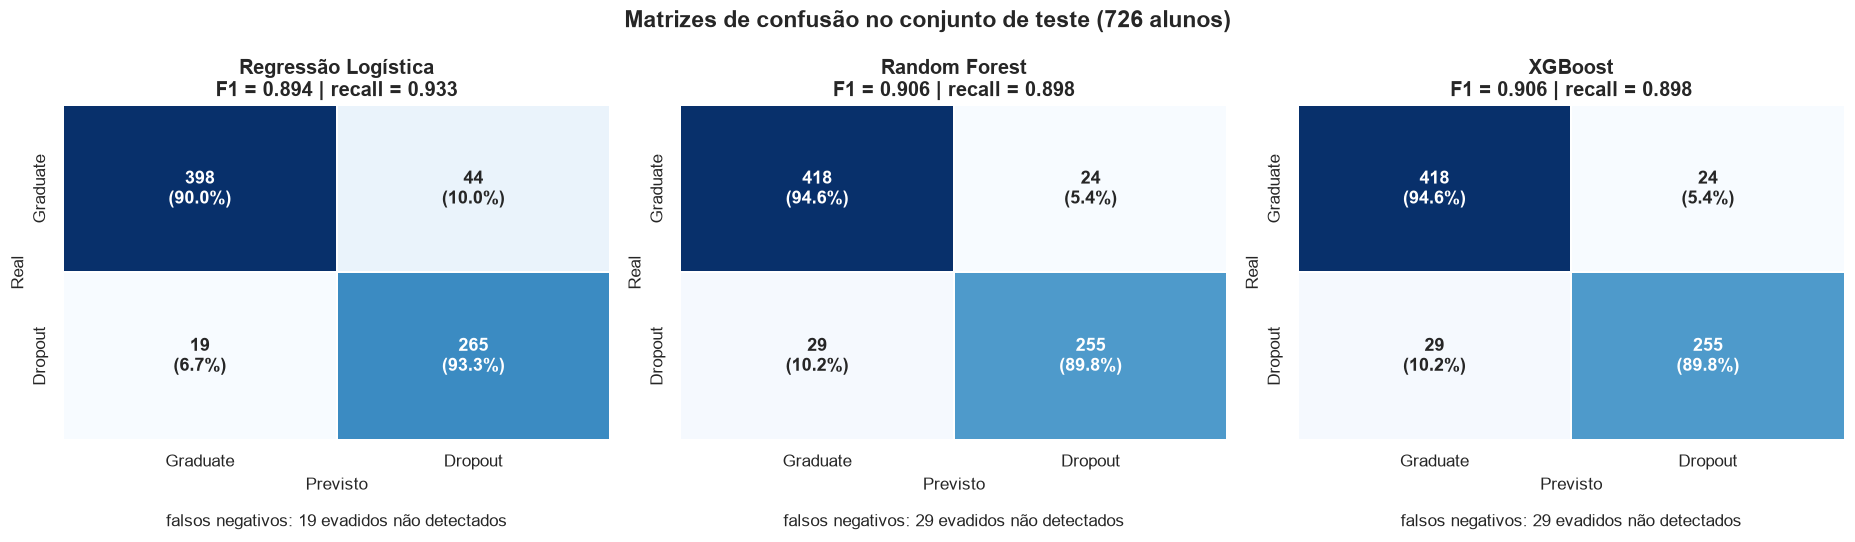

In [17]:
# --- Matrizes de confusão ----------------------------------------------------
fig, eixos = plt.subplots(1, 3, figsize=(17, 5))

for ax, (nome, pipeline) in zip(eixos, modelos_treinados.items()):
    y_pred = pipeline.predict(X_teste)
    mc, anotacoes = matriz_confusao_anotada(y_teste, y_pred)
    sns.heatmap(mc, annot=anotacoes, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=NOMES_CLASSES, yticklabels=NOMES_CLASSES,
                annot_kws={"size": 12, "weight": "bold"}, linewidths=1.2, linecolor="white")
    vn, fp, fn, vp = mc.ravel()
    ax.set_title(f"{nome}\nF1 = {resultados[nome]['F1']:.3f} | recall = {resultados[nome]['recall']:.3f}")
    ax.set_xlabel(f"Previsto\n\nfalsos negativos: {fn} evadidos não detectados")
    ax.set_ylabel("Real")

fig.suptitle("Matrizes de confusão no conjunto de teste (726 alunos)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
salvar("08_matrizes_confusao.png")
plt.show()

[figura salva] figuras\09_curvas_roc_pr.png


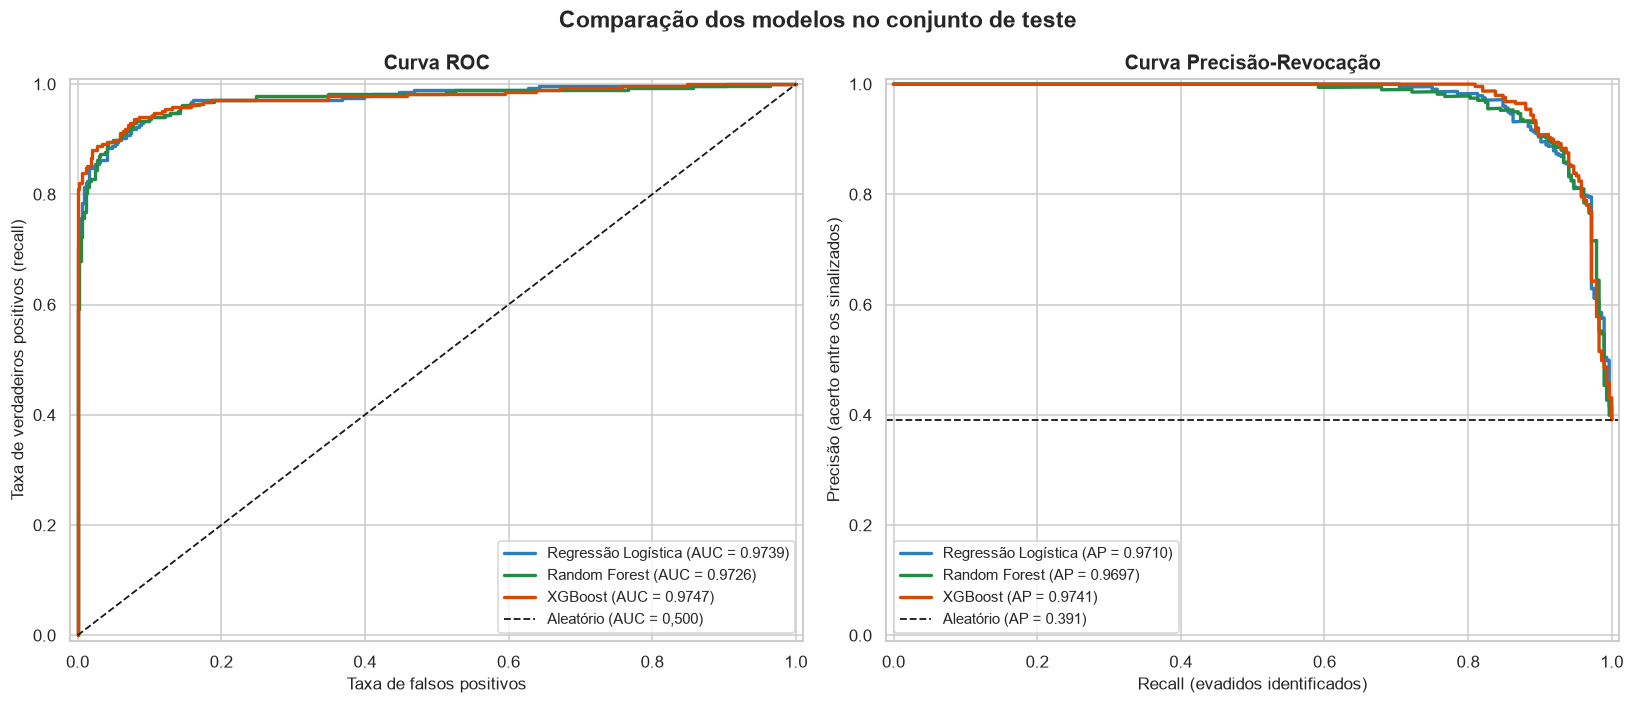

In [18]:
# --- Curvas ROC e Precisão-Revocação -----------------------------------------
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(15, 6.5))

for nome, pipeline in modelos_treinados.items():
    y_prob = pipeline.predict_proba(X_teste)[:, 1]
    cor = CORES_MODELO[nome]

    fpr, tpr, _ = roc_curve(y_teste, y_prob)
    ax_roc.plot(fpr, tpr, color=cor, linewidth=2.2,
                label=f"{nome} (AUC = {resultados[nome]['ROC-AUC']:.4f})")

    precisao, revocacao, _ = precision_recall_curve(y_teste, y_prob)
    ax_pr.plot(revocacao, precisao, color=cor, linewidth=2.2,
               label=f"{nome} (AP = {resultados[nome]['PR-AUC']:.4f})")

ax_roc.plot([0, 1], [0, 1], "k--", linewidth=1.2, label="Aleatório (AUC = 0,500)")
ax_roc.set_xlabel("Taxa de falsos positivos")
ax_roc.set_ylabel("Taxa de verdadeiros positivos (recall)")
ax_roc.set_title("Curva ROC")
ax_roc.legend(loc="lower right", fontsize=10)
ax_roc.set_xlim(-0.01, 1.01); ax_roc.set_ylim(-0.01, 1.01)

ax_pr.axhline(y_teste.mean(), color="k", linestyle="--", linewidth=1.2,
              label=f"Aleatório (AP = {y_teste.mean():.3f})")
ax_pr.set_xlabel("Recall (evadidos identificados)")
ax_pr.set_ylabel("Precisão (acerto entre os sinalizados)")
ax_pr.set_title("Curva Precisão-Revocação")
ax_pr.legend(loc="lower left", fontsize=10)
ax_pr.set_xlim(-0.01, 1.01); ax_pr.set_ylim(-0.01, 1.01)

fig.suptitle("Comparação dos modelos no conjunto de teste", fontsize=15, fontweight="bold")
plt.tight_layout()
salvar("09_curvas_roc_pr.png")
plt.show()

[figura salva] figuras\10_comparacao_metricas.png


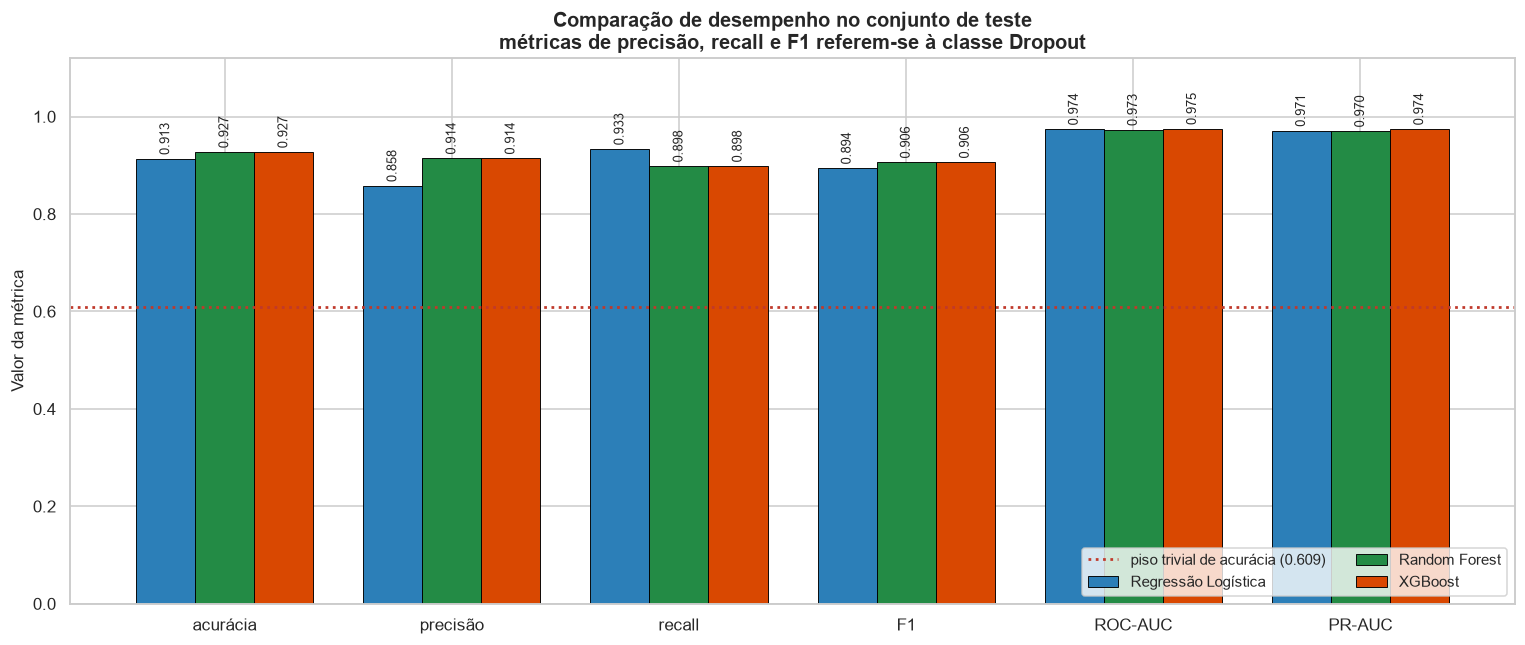

In [19]:
# --- Gráfico comparativo de métricas -----------------------------------------
metricas_grafico = ["acurácia", "precisão", "recall", "F1", "ROC-AUC", "PR-AUC"]
dados_grafico = comparacao[metricas_grafico].astype(float)

fig, ax = plt.subplots(figsize=(14, 6))
largura = 0.26
posicoes = np.arange(len(metricas_grafico))

for i, (nome, linha) in enumerate(dados_grafico.iterrows()):
    deslocamento = (i - 1) * largura
    barras = ax.bar(posicoes + deslocamento, linha.values, largura,
                    label=nome, color=CORES_MODELO[nome],
                    edgecolor="black", linewidth=0.6)
    for b, v in zip(barras, linha.values):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f"{v:.3f}",
                ha="center", fontsize=8.5, rotation=90, va="bottom")

ax.axhline(1 - y_teste.mean(), color="#c0392b", linestyle=":", linewidth=1.8,
           label=f"piso trivial de acurácia ({1 - y_teste.mean():.3f})")
ax.set_xticks(posicoes)
ax.set_xticklabels(metricas_grafico)
ax.set_ylabel("Valor da métrica")
ax.set_ylim(0, 1.12)
ax.set_title("Comparação de desempenho no conjunto de teste\n"
             "métricas de precisão, recall e F1 referem-se à classe Dropout")
ax.legend(loc="lower right", fontsize=10, ncol=2)
plt.tight_layout()
salvar("10_comparacao_metricas.png")
plt.show()

## 8. Seleção do modelo final

O critério é **F1 da classe `Dropout`**, com **recall** como primeiro desempate e **PR-AUC** como
segundo. A regra é aplicada programaticamente, para que a escolha não dependa de leitura visual das
tabelas.

O segundo desempate não é decorativo: como se verá, Random Forest e XGBoost **empatam exatamente**
em F1, recall e precisão neste conjunto de teste. Sem um terceiro critério declarado, o vencedor
seria decidido pela ordem de iteração do dicionário — o que não é um critério. Escolheu-se PR-AUC
porque ela avalia a qualidade do **ordenamento de probabilidades** em toda a faixa de limiares, e não
apenas a decisão binária em 0,50; é a métrica mais informativa para classe positiva minoritária.

In [20]:
criterio = (
    comparacao[["F1", "recall", "precisão", "ROC-AUC", "PR-AUC"]]
      .astype(float)
      .sort_values(["F1", "recall", "PR-AUC"], ascending=False)
)
display(criterio.round(4))

MELHOR = criterio.index[0]
melhor_pipeline = modelos_treinados[MELHOR]

print(f"MODELO SELECIONADO: {MELHOR}")
print()
segundo = criterio.index[1]
delta_f1 = criterio.loc[MELHOR, "F1"] - criterio.loc[segundo, "F1"]
print(f"Vantagem de F1 sobre o 2º colocado ({segundo}): {delta_f1:+.4f}")

base = "Regressão Logística"
if MELHOR != base:
    ganho = criterio.loc[MELHOR, "F1"] - criterio.loc[base, "F1"]
    print(f"Ganho de F1 sobre a linha de base linear: {ganho:+.4f} "
          f"({ganho / criterio.loc[base, 'F1'] * 100:+.1f}%)")

if abs(delta_f1) < 1e-9:
    print()
    print(f"Empate exato em F1 com {segundo}. Desempate aplicado:")
    print(f"   recall  -> {MELHOR}: {criterio.loc[MELHOR, 'recall']:.4f} | "
          f"{segundo}: {criterio.loc[segundo, 'recall']:.4f}")
    print(f"   PR-AUC  -> {MELHOR}: {criterio.loc[MELHOR, 'PR-AUC']:.4f} | "
          f"{segundo}: {criterio.loc[segundo, 'PR-AUC']:.4f}")

,F1,recall,precisão,ROC-AUC,PR-AUC
XGBoost,0.9059,0.8979,0.9140,0.9747,0.9741
Random Forest,0.9059,0.8979,0.9140,0.9726,0.9697
Regressão Logística,0.8938,0.9331,0.8576,0.9739,0.9710


MODELO SELECIONADO: XGBoost

Vantagem de F1 sobre o 2º colocado (Random Forest): +0.0000
Ganho de F1 sobre a linha de base linear: +0.0121 (+1.4%)

Empate exato em F1 com Random Forest. Desempate aplicado:
   recall  -> XGBoost: 0.8979 | Random Forest: 0.8979
   PR-AUC  -> XGBoost: 0.9741 | Random Forest: 0.9697


In [21]:
# --- O empate nas métricas significa modelos iguais? -------------------------
# Vale investigar: métricas idênticas não implicam predições idênticas.
pred_por_modelo = {nome: pipe.predict(X_teste) for nome, pipe in modelos_treinados.items()}

print("Discordância entre pares de modelos (de 726 alunos):")
nomes = list(pred_por_modelo)
for i in range(len(nomes)):
    for j in range(i + 1, len(nomes)):
        divergentes = int((pred_por_modelo[nomes[i]] != pred_por_modelo[nomes[j]]).sum())
        print(f"   {nomes[i]:<22} x {nomes[j]:<22} {divergentes:>3} alunos "
              f"({divergentes / len(y_teste) * 100:.1f}%)")

rf_xgb = pred_por_modelo.get("Random Forest") != pred_por_modelo.get("XGBoost")
print()
print(f"Random Forest e XGBoost discordam sobre {int(rf_xgb.sum())} alunos, mas produzem")
print("matrizes de confusão idênticas — os erros de um compensam exatamente os do outro.")
print("Não são o mesmo modelo; são dois modelos diferentes com o mesmo placar agregado.")
print()
print("Concordância dos três modelos simultaneamente:")
todos_iguais = np.all([pred_por_modelo[n] == pred_por_modelo[nomes[0]] for n in nomes], axis=0)
print(f"   {int(todos_iguais.sum())} de {len(y_teste)} alunos ({todos_iguais.mean() * 100:.1f}%) recebem a mesma classificação dos três")

Discordância entre pares de modelos (de 726 alunos):
   Regressão Logística    x Random Forest           54 alunos (7.4%)
   Regressão Logística    x XGBoost                 52 alunos (7.2%)
   Random Forest          x XGBoost                 24 alunos (3.3%)

Random Forest e XGBoost discordam sobre 24 alunos, mas produzem
matrizes de confusão idênticas — os erros de um compensam exatamente os do outro.
Não são o mesmo modelo; são dois modelos diferentes com o mesmo placar agregado.

Concordância dos três modelos simultaneamente:
   661 de 726 alunos (91.0%) recebem a mesma classificação dos três


> ### Um achado que vale para a monografia
>
> Random Forest e XGBoost produzem **matrizes de confusão idênticas** (418 / 24 / 29 / 255 nesta
> partição) e, no entanto, **discordam sobre 24 alunos** — e nesses 24, cada modelo acerta exatamente
> 12. Os erros de um compensam os do outro no agregado. A identidade das matrizes é uma propriedade
> desta partição; o que não depende dela é o fato de serem **modelos distintos**, evidenciado pelas
> probabilidades diferentes (correlação 0,9712).
>
> Isso ilustra um limite das métricas agregadas que costuma passar em branco: elas resumem o placar,
> não a decisão individual. Dois modelos com F1 igual podem sinalizar conjuntos diferentes de alunos —
> e, quando o produto final é uma lista de nomes para a coordenação abordar, essa diferença é
> justamente o que importa.
>
> É outro argumento a favor da abordagem do Notebook 4: comparar modelos apenas por métricas
> agregadas é insuficiente quando o uso pretendido é individual. A explicação por aluno não é um
> adorno do trabalho — é parte da avaliação.

### Sobre a magnitude da diferença entre os modelos

Este é o ponto em que a honestidade metodológica importa mais do que a preferência por um algoritmo.
As diferenças de F1 entre os três modelos são **pequenas em termos absolutos**. Com 726 registros de
teste, uma diferença de 0,01 em F1 corresponde a poucos alunos reclassificados — dentro da faixa em
que uma partição diferente dos dados poderia inverter o ranking.

A conclusão defensável, portanto, não é "o algoritmo X é superior", e sim:

> **O sinal preditivo está nos dados, não no algoritmo.** Os três modelos convergem para um patamar
> semelhante porque as variáveis de desempenho acadêmico e situação financeira carregam quase toda a
> informação disponível. Trocar de algoritmo rende pouco; o que renderia mais seria observar o aluno
> mais cedo ou coletar variáveis novas.

Esse achado tem uma consequência prática favorável ao objetivo do TCC: como não há custo relevante
de desempenho em escolher um modelo mais interpretável, a **interpretabilidade pode ser tratada como
critério legítimo de decisão**, e não como concessão. É o que o Notebook 4 explora.

## 9. A contradição entre o critério de seleção e a premissa de custo

**Há uma contradição a resolver, e não a suavizar.**

O trabalho declara desde a Fase 3 (decisão D-10) que **falso negativo custa mais que falso positivo** —
perder um aluno que evade é pior que uma conversa desnecessária. Essa premissa prioriza **recall**. Mas
o critério de seleção adotado foi **F1**, que pesa os dois erros igualmente.

E os números mostram que a tensão não é retórica:

| Partição da semente 42 | Regressão Logística | XGBoost |
|---|---:|---:|
| Evadidos detectados | **265** de 284 | 255 de 284 |
| Evadidos perdidos | **19** | 29 |
| Falsos alarmes | 44 | **24** |
| Alunos convocados | 309 — 42,6% | **279 — 38,4%** |
| F1 | 0,8938 | **0,9059** |

Todas as contagens desta tabela são da partição da semente 42. Em partições típicas o XGBoost detecta
240 evadidos em vez de 255 e perde 44 em vez de 29 (Verificação 2). A **comparação entre os dois
modelos** permanece válida, porque ambos são avaliados sobre exatamente os mesmos alunos.

A Regressão Logística encontra **10 evadidos a mais** ao custo de **20 convocações a mais**. O F1
penaliza esse desequilíbrio; o recall isolado o premiaria. Dizer apenas "o critério declarado foi F1"
reafirma a escolha em vez de justificá-la.

### 9.1 O erro estava em tratar duas decisões como uma

O trabalho vinha misturando duas perguntas independentes:

| Pergunta | Mecanismo de resposta |
|---|---|
| **Qual algoritmo usar?** | Comparação por F1 / PR-AUC |
| **Como calibrar o trade-off recall × precisão?** | **O limiar de decisão** |

Comparar os dois modelos **cada um no seu limiar padrão de 0,50** é comparar pontos de operação
diferentes: a Regressão Logística opera em recall 0,933 e o XGBoost em 0,898. A comparação correta
exige **igualar o ponto de operação** — e para isso é preciso a curva de custo de cada modelo.

### 9.2 A curva de custo exata

Em vez de varrer uma grade de limiares e interpolar, calcula-se a curva **exata**: ordenando os alunos
pelo escore de risco, para cada número de evadidos detectados obtém-se o **mínimo de falsos alarmes**
que aquele modelo precisa pagar.

Isso elimina a interpolação e atinge a resolução máxima possível — **um aluno**. Note que o recall só
pode assumir valores múltiplos de 1/284 = 0,0035; resoluções mais finas que isso são matematicamente
inalcançáveis.

In [22]:
# --- Curva de custo exata dos dois modelos ---------------------------------
N_EVADIDOS = int(y_teste.sum())
N_TURMA = len(y_teste)

def curva_custo_exata(escores):
    """Para cada nº de evadidos detectados, o MÍNIMO de falsos alarmes necessário.

    Ordena os alunos por escore decrescente e percorre todos os pontos de corte
    possíveis — sem grade de limiares e sem interpolação.
    """
    ordem = np.argsort(-escores)
    rotulos = y_teste.to_numpy()[ordem]
    detectados = np.cumsum(rotulos == 1)
    falsos = np.cumsum(rotulos == 0)
    minimo = {}
    for d, f in zip(detectados, falsos):
        if d not in minimo or f < minimo[d]:
            minimo[d] = int(f)
    return minimo

escores = {nome: pipe.predict_proba(X_teste)[:, 1]
           for nome, pipe in modelos_treinados.items()}
custo = {nome: curva_custo_exata(e) for nome, e in escores.items()}

comuns = sorted(set(custo["XGBoost"]) & set(custo["Regressão Logística"]))
curva = pd.DataFrame({
    "detectados": comuns,
    "recall": [k / N_EVADIDOS for k in comuns],
    "fa_xgboost": [custo["XGBoost"][k] for k in comuns],
    "fa_reg_logistica": [custo["Regressão Logística"][k] for k in comuns],
})
curva["dif"] = curva["fa_reg_logistica"] - curva["fa_xgboost"]
curva["conv_xgboost"] = curva["detectados"] + curva["fa_xgboost"]
curva["conv_reg_logistica"] = curva["detectados"] + curva["fa_reg_logistica"]

print(f"Curva exata construída: {len(curva)} pontos de operação alcançáveis")
print(f"Granularidade mínima do recall: 1/{N_EVADIDOS} = {1 / N_EVADIDOS:.5f}")
curva.to_csv(os.path.join(DIR_DADOS, "curva_custo_exata.csv"), index=False, encoding="utf-8")
print(f"[salvo] {os.path.join(DIR_DADOS, 'curva_custo_exata.csv')}")

Curva exata construída: 284 pontos de operação alcançáveis
Granularidade mínima do recall: 1/284 = 0.00352


[salvo] dados\curva_custo_exata.csv


In [23]:
# --- Comparação ISOCUSTO: mesmo nº de falsos alarmes -----------------------
def detectados_com(fa_max, coluna):
    """Máximo de evadidos detectáveis sem passar de `fa_max` falsos alarmes."""
    elegiveis = curva[curva[coluna] <= fa_max]
    return int(elegiveis["detectados"].max()) if len(elegiveis) else 0

print("COMPARAÇÃO ISOCUSTO — quantos evadidos cada modelo detecta pagando o mesmo preço")
print()
print(f"   {'falsos alarmes':>15} {'XGBoost':>9} {'Reg. Log.':>10} {'diferença':>11}")
linhas_iso = []
for fa in (24, 35, 40, 44, 58):
    dx = detectados_com(fa, "fa_xgboost")
    dl = detectados_com(fa, "fa_reg_logistica")
    linhas_iso.append({"falsos alarmes": fa, "XGBoost": dx, "Reg. Logística": dl,
                       "diferença": dx - dl})
    print(f"   {fa:>15} {dx:>9} {dl:>10} {dx - dl:>+11}")

print()
print("A vantagem do XGBoost oscila entre +1 e +5 evadidos dependendo do ponto de custo.")
print("Reportar um único ponto esconderia essa variação.")
print()
print("ACHADO ADICIONAL — o limiar 0,50 não é ótimo nem para a Regressão Logística:")
lr50 = int(((escores['Regressão Logística'] >= 0.50) &
            (y_teste.to_numpy() == 1)).sum())
fa50 = int(((escores['Regressão Logística'] >= 0.50) & (y_teste.to_numpy() == 0)).sum())
fa_min = int(curva.loc[curva.detectados == lr50, 'fa_reg_logistica'].iloc[0])
print(f"   no limiar 0,50 ela detecta {lr50} evadidos pagando {fa50} falsos alarmes")
print(f"   na sua própria curva, {lr50} evadidos custam apenas {fa_min} falsos alarmes")
print(f"   -> o limiar padrão desperdiça {fa50 - fa_min} convocações do próprio modelo")

COMPARAÇÃO ISOCUSTO — quantos evadidos cada modelo detecta pagando o mesmo preço

    falsos alarmes   XGBoost  Reg. Log.   diferença
                24       255        254          +1
                35       266        261          +5
                40       267        265          +2
                44       267        266          +1
                58       272        269          +3

A vantagem do XGBoost oscila entre +1 e +5 evadidos dependendo do ponto de custo.
Reportar um único ponto esconderia essa variação.

ACHADO ADICIONAL — o limiar 0,50 não é ótimo nem para a Regressão Logística:
   no limiar 0,50 ela detecta 265 evadidos pagando 44 falsos alarmes
   na sua própria curva, 265 evadidos custam apenas 40 falsos alarmes
   -> o limiar padrão desperdiça 4 convocações do próprio modelo


### 9.3 O limiar 0,50 não é ótimo nem para o próprio modelo

A célula acima revela algo que vale destacar, porque é evidência **independente** de todas as outras: no
limiar padrão de 0,50 a Regressão Logística detecta 265 evadidos pagando **44** falsos alarmes — mas a
sua própria curva de custo mostra que os mesmos 265 evadidos são alcançáveis com apenas **40**.

O limiar padrão **desperdiça 4 convocações do próprio modelo**, sem ganho algum em detecção.

> Isso demonstra, sem comparar modelo com modelo, que **0,50 é convenção de biblioteca e não ponto de
> operação de nenhum dos dois**. É a versão mais econômica do argumento central desta seção: o limiar
> importa, e tratá-lo como valor padrão é deixar desempenho na mesa.

### 9.4 Comparação isorecall e as três regiões

In [24]:
# --- Comparação ISORECALL e o mapeamento das regiões ----------------------
print("COMPARAÇÃO ISORECALL — custo de cada modelo no mesmo nível de recall")
print()
print(f"   {'detectados':>11} {'recall':>8} {'XGB':>6} {'Reg.Log.':>9} {'vantagem XGB':>13}")
for k in (255, 260, 265, 267, 270, 272):
    r = curva[curva.detectados == k]
    if not len(r):
        continue
    r = r.iloc[0]
    print(f"   {k:>11} {r.recall:>8.4f} {int(r.fa_xgboost):>6} "
          f"{int(r.fa_reg_logistica):>9} {int(r.dif):>+13}")

TETO_CONVOCACAO = 0.50 * N_TURMA     # metade da turma: limite de utilidade da triagem
FIM_ESTAVEL = 272

print()
print("AS TRÊS REGIÕES DA CURVA")
print()
regioes = [
    ("estável", curva[(curva.recall >= 0.85) & (curva.detectados <= FIM_ESTAVEL)]),
    ("banda estreita", curva[(curva.detectados >= 273) & (curva.detectados <= 276)]),
    ("instável", curva[curva.detectados >= 277]),
]
for nome, d in regioes:
    if not len(d):
        continue
    conv_min = min(d.conv_xgboost.min(), d.conv_reg_logistica.min())
    conv_max = max(d.conv_xgboost.max(), d.conv_reg_logistica.max())
    print(f"   {nome.upper()} — recall {d.recall.min():.4f} a {d.recall.max():.4f} "
          f"({len(d)} pontos)")
    print(f"      XGBoost melhor em {int((d.dif > 0).sum())}, "
          f"Reg. Logística melhor em {int((d.dif < 0).sum())}")
    print(f"      diferença: {int(d.dif.abs().min())} a {int(d.dif.abs().max())} falsos alarmes")
    print(f"      convocados: {conv_min / N_TURMA:.1%} a {conv_max / N_TURMA:.1%} da turma")
    print()

inversoes = [int(curva.detectados.iloc[i]) for i in range(1, len(curva))
             if np.sign(curva.dif.iloc[i]) != np.sign(curva.dif.iloc[i - 1])
             and curva.dif.iloc[i] != 0 and 270 <= curva.detectados.iloc[i] < N_EVADIDOS]
# exclui o ponto degenerado recall = 1,0, em que ambos os modelos sao obrigados a
# sinalizar todos os evadidos e a comparacao perde sentido operacional.
print(f"Travessias de liderança a partir de 270 detectados: {inversoes}")
print(f"Pontos vencidos pela Reg. Logística na curva inteira: {int((curva.dif < 0).sum())}")
sob_teto = curva[curva.conv_xgboost <= TETO_CONVOCACAO]
print(f"Abaixo do teto: XGBoost melhor em {int((sob_teto.dif > 0).sum())}, "
      f"Reg. Logística em {int((sob_teto.dif < 0).sum())}, "
      f"de {int((sob_teto.dif != 0).sum())} pontos decididos")
print(f"Teto de convocação adotado: {TETO_CONVOCACAO:.0f} alunos (50% da turma)")

COMPARAÇÃO ISORECALL — custo de cada modelo no mesmo nível de recall

    detectados   recall    XGB  Reg.Log.  vantagem XGB
           255   0.8979     23        25            +2
           260   0.9155     28        33            +5
           265   0.9331     35        40            +5
           267   0.9401     38        45            +7
           270   0.9507     52        63           +11
           272   0.9577     58        63            +5

AS TRÊS REGIÕES DA CURVA

   ESTÁVEL — recall 0.8521 a 0.9577 (31 pontos)
      XGBoost melhor em 31, Reg. Logística melhor em 0
      diferença: 1 a 11 falsos alarmes
      convocados: 34.2% a 46.1% da turma

   BANDA ESTREITA — recall 0.9613 a 0.9718 (4 pontos)
      XGBoost melhor em 0, Reg. Logística melhor em 4
      diferença: 1 a 11 falsos alarmes
      convocados: 47.1% a 49.3% da turma

   INSTÁVEL — recall 0.9754 a 1.0000 (8 pontos)
      XGBoost melhor em 3, Reg. Logística melhor em 5
      diferença: 9 a 75 falsos alarmes
    

[figura salva] figuras\25_curvas_custo_pareadas.png


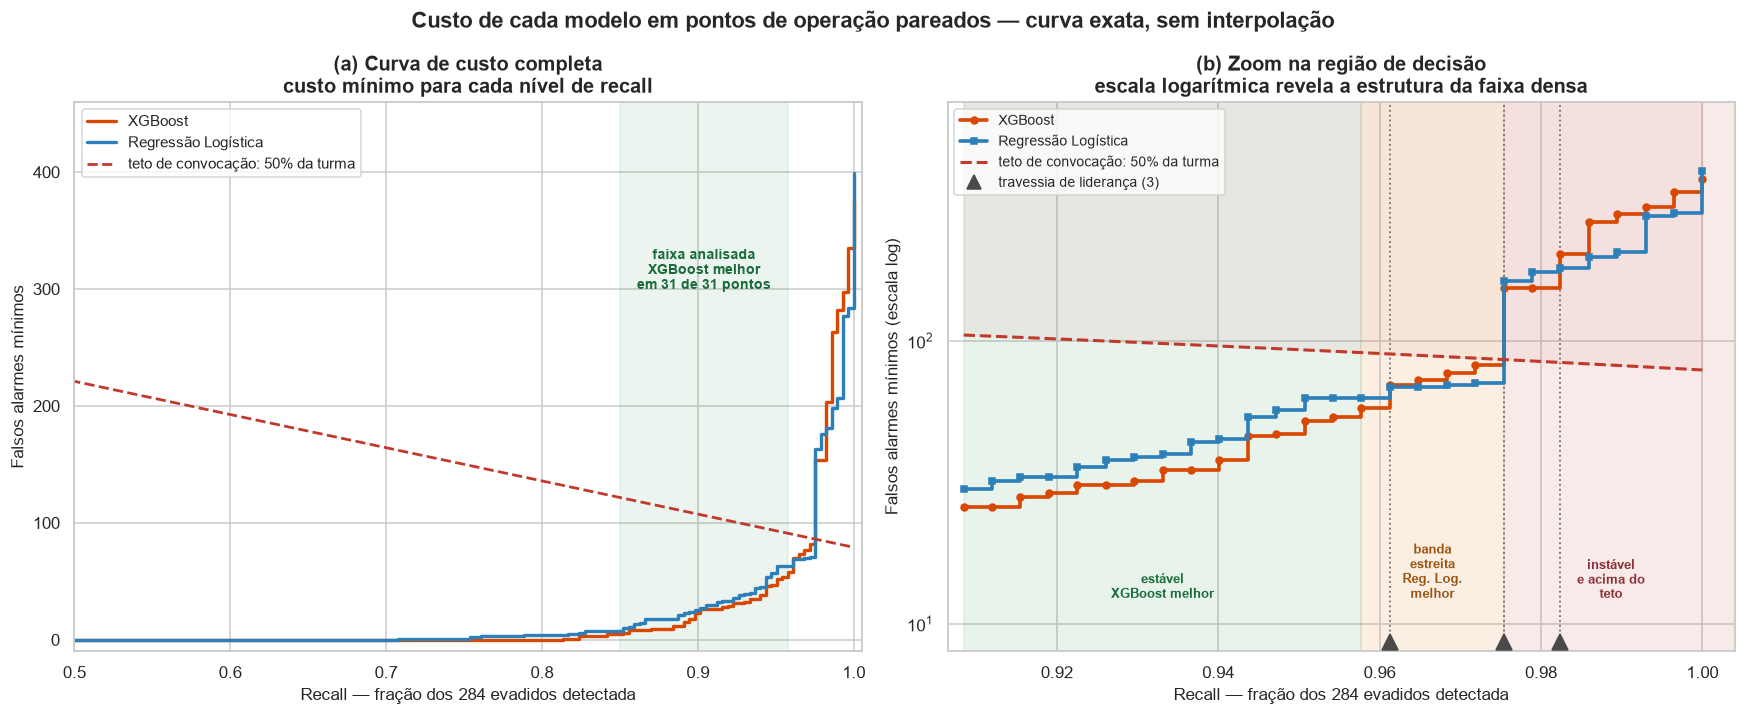

In [25]:
# --- Figura: curvas de custo pareadas -------------------------------------
C_XGB, C_LR = "#d94801", "#2c7fb8"
INICIO_INSTAVEL = 277

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.6))

# (a) curva completa
ax1.step(curva.recall, curva.fa_xgboost, where="post", color=C_XGB, linewidth=2.2,
         label="XGBoost")
ax1.step(curva.recall, curva.fa_reg_logistica, where="post", color=C_LR, linewidth=2.2,
         label="Regressão Logística")
ax1.axvspan(0.85, FIM_ESTAVEL / N_EVADIDOS, color="#238b45", alpha=0.09)
ax1.text((0.85 + FIM_ESTAVEL / N_EVADIDOS) / 2, 300,
         "faixa analisada\nXGBoost melhor\nem 31 de 31 pontos",
         ha="center", fontsize=9, color="#1a6b3a", fontweight="bold")
# O teto NÃO é um valor fixo de falsos alarmes: convocados = detectados + falsos
# alarmes, logo o teto é a reta FA = TETO - detectados.
ax1.plot(curva.recall, TETO_CONVOCACAO - curva.detectados, color="#c0392b",
         linestyle="--", linewidth=1.8, label="teto de convocação: 50% da turma")
ax1.set_xlabel("Recall — fração dos 284 evadidos detectada")
ax1.set_ylabel("Falsos alarmes mínimos")
ax1.set_title("(a) Curva de custo completa\ncusto mínimo para cada nível de recall")
ax1.legend(loc="upper left", fontsize=9.5)
ax1.set_xlim(0.5, 1.005)
ax1.set_ylim(-10, 460)

# (b) zoom com escala log
z = curva[(curva.detectados >= 258) & (curva.detectados <= 284)]
ax2.step(z.recall, z.fa_xgboost, where="post", color=C_XGB, linewidth=2.4,
         marker="o", markersize=4.5, label="XGBoost")
ax2.step(z.recall, z.fa_reg_logistica, where="post", color=C_LR, linewidth=2.4,
         marker="s", markersize=4.5, label="Regressão Logística")

lim_est = FIM_ESTAVEL / N_EVADIDOS
lim_inst = INICIO_INSTAVEL / N_EVADIDOS
ax2.axvspan(z.recall.min(), lim_est, color="#238b45", alpha=0.10)
ax2.axvspan(lim_est, lim_inst, color="#e6842a", alpha=0.13)
ax2.axvspan(lim_inst, 1.005, color="#c0392b", alpha=0.10)

teto_fa = TETO_CONVOCACAO - z.detectados
ax2.plot(z.recall, teto_fa, color="#c0392b", linestyle="--", linewidth=2,
         label="teto de convocação: 50% da turma")
ax2.fill_between(z.recall, teto_fa, 1e4, color="#c0392b", alpha=0.055)

for k in inversoes:
    r = curva[curva.detectados == k]
    if not len(r):
        continue
    ax2.axvline(r.iloc[0].recall, color="#4a4a4a", linestyle=":", linewidth=1.2,
                alpha=0.75, zorder=1)
    ax2.plot(r.iloc[0].recall, 8.6, marker="^", color="#4a4a4a", markersize=10,
             clip_on=False, zorder=6)
ax2.plot([], [], marker="^", color="#4a4a4a", linestyle="none", markersize=9,
         label=f"travessia de liderança ({len(inversoes)})")

ax2.set_yscale("log")
ax2.set_ylim(8, 700)
ax2.set_xlim(z.recall.min() - 0.002, 1.004)
ax2.set_xlabel("Recall — fração dos 284 evadidos detectada")
ax2.set_ylabel("Falsos alarmes mínimos (escala log)")
ax2.set_title("(b) Zoom na região de decisão\nescala logarítmica revela a estrutura da faixa densa")
ax2.legend(loc="upper left", fontsize=9)

for x, texto, cor in [((z.recall.min() + lim_est) / 2, "estável\nXGBoost melhor", "#1a6b3a"),
                      ((lim_est + lim_inst) / 2, "banda\nestreita\nReg. Log.\nmelhor", "#9a5410"),
                      ((lim_inst + 1.002) / 2, "instável\ne acima do\nteto", "#8c2f39")]:
    ax2.text(x, 12, texto, ha="center", va="bottom", fontsize=8.5, color=cor,
             fontweight="bold")

fig.suptitle("Custo de cada modelo em pontos de operação pareados — curva exata, sem interpolação",
             fontsize=14.5, fontweight="bold", y=0.98)
plt.tight_layout()
salvar("25_curvas_custo_pareadas.png")
plt.show()

> ### Leitura — a contradição resolvida
>
> Com os dois limiares livres, a curva exata mostra **três regiões distintas**:
>
> | Região | Recall | Pontos | Melhor modelo | Convocados |
> |---|---|---:|---|---|
> | **Estável** | 0,852 – 0,9577 | 31 | **XGBoost** em 31 de 31 | 34% a 46% da turma |
> | **Banda estreita** | 0,9613 – 0,9718 | 4 | **Reg. Logística** em 4 de 4 | 47% a 49% da turma |
> | **Instável** | ≥ 0,9754 | 8 | oscila — 3 travessias de liderança | 59% a 94% da turma |
>
> *A coluna “Convocados” considera os dois modelos; pelo XGBoost isoladamente seriam 34%–45%,
> 47%–49% e 59%–91%.*
>
> **A manchete:** na faixa de recall 0,852 a 0,9577 o XGBoost vence em **31 de 31** pontos de operação,
> convocando de 34% a 46% da turma.
>
> **A banda estreita está DENTRO do teto de 50%, e isso precisa ser dito.** Entre recall 0,961 e 0,972
> — quatro pontos consecutivos — a Regressão Logística é consistentemente melhor, por 1 a 11 falsos
> alarmes, convocando de **47% a 49%** da turma. Não é oscilação ali, e também não é um regime
> descartável: são os últimos quatro pontos antes do teto. A contabilidade completa abaixo da
> fronteira prática é **72 pontos para o XGBoost e 4 para a Regressão Logística**, de 76 decididos
> (os demais empatam). Adotar 62% em vez de 50% como teto levaria a 74 × 4 — as mesmas quatro
> inversões, porque o segundo bloco só começa a 66% de convocação.
>
> **Duas contagens diferentes, que não devem ser confundidas:** a curva tem **9 pontos** em que a
> Regressão Logística vence (273–276 e 279–283) e **3 travessias de liderança** (273, 277, 279) — os
> pontos em que o modelo vencedor muda. Uma quarta travessia, em recall 1,0, é degenerada e foi
> excluída.
>
> ### O que isso resolve
>
> **A vantagem de recall da Regressão Logística não é artefato — mas também não é geral.** Ela é real no
> limiar 0,50 (e o teste de McNemar da Verificação 2 a confirma como estatisticamente significativa
> *naquele ponto de operação*), e reaparece numa banda estreita de recall muito alto que ainda cabe
> dentro do teto de convocação. O enunciado correto não é que o XGBoost vença em toda a faixa
> utilizável, e sim que ele vence em **72 dos 76 pontos decididos** abaixo do teto de 50%.
>
> **Por que F1 permanece o critério de seleção entre algoritmos:**
>
> 1. **Comparabilidade com a literatura.** F1 é a métrica predominante nos trabalhos que usam esta base.
> 2. **A magnitude absoluta é pequena em qualquer ponto pareado.** No isocusto, a vantagem do XGBoost
>    fica entre +1 e +5 evadidos; a diferença entre os modelos é menor que a variação induzida pela
>    partição dos dados (ver Verificação 2).
>
> ### A hierarquia correta de decisão
>
> | Ordem | Decisão | Quem decide |
> |---:|---|---|
> | 1º | **Política de custo** — quantas convocações desnecessárias valem a pena para não perder um aluno? | A instituição |
> | 2º | **Limiar de decisão** que implementa essa política | Derivado de 1, pela tabela de cenários |
> | 3º | **Algoritmo** — só relevante se a política exigir recall acima de 0,96 | Técnico |
>
> O trabalho vinha invertendo essa ordem, tratando a escolha do algoritmo como a decisão central. Ela é
> a **menos** importante das três.
>
> ### A Regressão Logística como alternativa legítima
>
> Isto não é nota de rodapé. Uma instituição pode preferir o modelo linear por três razões:
>
> - **Simplicidade e transparência** — coeficientes lineares são auditáveis sem SHAP;
> - **Sem perda relevante de desempenho** — os intervalos de confiança de *bootstrap* dos três modelos
>   se sobrepõem em todas as métricas;
> - **Vantagem real no regime de recall muito alto** (0,961 a 0,972) — que está dentro do teto de 50%,
>   não fora dele, e exige convocar de 47% a 49% da turma.
>
> *Ressalva:* qualquer limiar localizado por busca no conjunto de teste é **ilustrativo do formato da
> curva**, não um valor a adotar operacionalmente sem validação em dados novos.

In [26]:
# --- Relatório detalhado do modelo escolhido ---------------------------------
y_pred_melhor = melhor_pipeline.predict(X_teste)
y_prob_melhor = melhor_pipeline.predict_proba(X_teste)[:, 1]

print(f"MODELO FINAL: {MELHOR}")
print("=" * 64)
print(classification_report(y_teste, y_pred_melhor, target_names=NOMES_CLASSES, digits=4))

mc = confusion_matrix(y_teste, y_pred_melhor)
vn, fp, fn, vp = mc.ravel()

print("Tradução da matriz de confusão para a gestão acadêmica:")
print(f"   {vp:>3} evadidos corretamente sinalizados   (verdadeiros positivos)")
print(f"   {fn:>3} evadidos NÃO detectados             (falsos negativos — o erro caro)")
print(f"   {fp:>3} concluintes sinalizados por engano  (falsos positivos — custo de uma conversa)")
print(f"   {vn:>3} concluintes corretamente liberados  (verdadeiros negativos)")
print()
print(f"De cada 100 alunos que evadem, o modelo identifica {vp / (vp + fn) * 100:.0f}.")
print(f"De cada 100 alunos sinalizados, {vp / (vp + fp) * 100:.0f} realmente evadiriam.")
print(f"Total de alunos sinalizados: {vp + fp} de {len(y_teste)} ({(vp + fp) / len(y_teste) * 100:.1f}% da turma).")

MODELO FINAL: XGBoost
              precision    recall  f1-score   support

    Graduate     0.9351    0.9457    0.9404       442
     Dropout     0.9140    0.8979    0.9059       284

    accuracy                         0.9270       726
   macro avg     0.9246    0.9218    0.9231       726
weighted avg     0.9269    0.9270    0.9269       726

Tradução da matriz de confusão para a gestão acadêmica:
   255 evadidos corretamente sinalizados   (verdadeiros positivos)
    29 evadidos NÃO detectados             (falsos negativos — o erro caro)
    24 concluintes sinalizados por engano  (falsos positivos — custo de uma conversa)
   418 concluintes corretamente liberados  (verdadeiros negativos)

De cada 100 alunos que evadem, o modelo identifica 90.
De cada 100 alunos sinalizados, 91 realmente evadiriam.
Total de alunos sinalizados: 279 de 726 (38.4% da turma).


## 9. Ajuste do limiar de decisão

Todas as métricas até aqui usaram o limiar padrão de **0,5**: o aluno é sinalizado se a
probabilidade estimada de evasão passar de 50%. Esse valor é uma convenção de biblioteca, não uma
decisão pedagógica — e não há razão para que coincida com o ponto ótimo de uso.

Como o objetivo declarado do trabalho é priorizar o **recall da classe `Dropout`**, faz sentido
examinar o que se ganha e o que se perde ao deslocar o limiar. Baixá-lo aumenta o recall (menos
evadidos escapam) ao custo de precisão (mais concluintes sinalizados sem necessidade).

O que a instituição precisa decidir é: **quantas conversas desnecessárias vale a pena ter para não
perder um aluno?** A análise abaixo transforma essa pergunta em números.

In [27]:
limiares = np.arange(0.05, 0.96, 0.01)
curva = []
for t in limiares:
    pred = (y_prob_melhor >= t).astype(int)
    curva.append({
        "limiar": t,
        "precisão": precision_score(y_teste, pred, zero_division=0),
        "recall": recall_score(y_teste, pred, zero_division=0),
        "F1": f1_score(y_teste, pred, zero_division=0),
        "sinalizados": int(pred.sum()),
    })
curva = pd.DataFrame(curva)

limiar_f1 = curva.loc[curva["F1"].idxmax(), "limiar"]
limiar_r90 = curva[curva["recall"] >= 0.90]["limiar"].max()

print(f"Limiar padrão                  : 0.50  -> F1 {curva.loc[curva['limiar'].sub(0.5).abs().idxmin(), 'F1']:.4f}")
print(f"Limiar que maximiza F1         : {limiar_f1:.2f}  -> F1 {curva['F1'].max():.4f}")
if not np.isnan(limiar_r90):
    linha = curva[curva["limiar"] == limiar_r90].iloc[0]
    print(f"Limiar para recall >= 90%      : {limiar_r90:.2f}  -> recall {linha['recall']:.4f}, precisão {linha['precisão']:.4f}")

print("\nCenários operacionais:")
tabela_cenarios = curva[curva["limiar"].isin([0.20, 0.30, 0.40, 0.50, 0.60, 0.70])].copy()
tabela_cenarios["evadidos perdidos"] = ((1 - tabela_cenarios["recall"]) * y_teste.sum()).round().astype(int)
tabela_cenarios["falsos alarmes"] = (tabela_cenarios["sinalizados"]
                                     - (tabela_cenarios["recall"] * y_teste.sum()).round()).astype(int)
display(tabela_cenarios.set_index("limiar").round(4))

Limiar padrão                  : 0.50  -> F1 0.9059
Limiar que maximiza F1         : 0.64  -> F1 0.9191
Limiar para recall >= 90%      : 0.49  -> recall 0.9014, precisão 0.9078

Cenários operacionais:


,precisão,recall,F1,sinalizados,evadidos perdidos,falsos alarmes
limiar,,,,,,
0.2,0.7541,0.9718,0.8492,366,8,90


[figura salva] figuras\11_analise_limiar.png


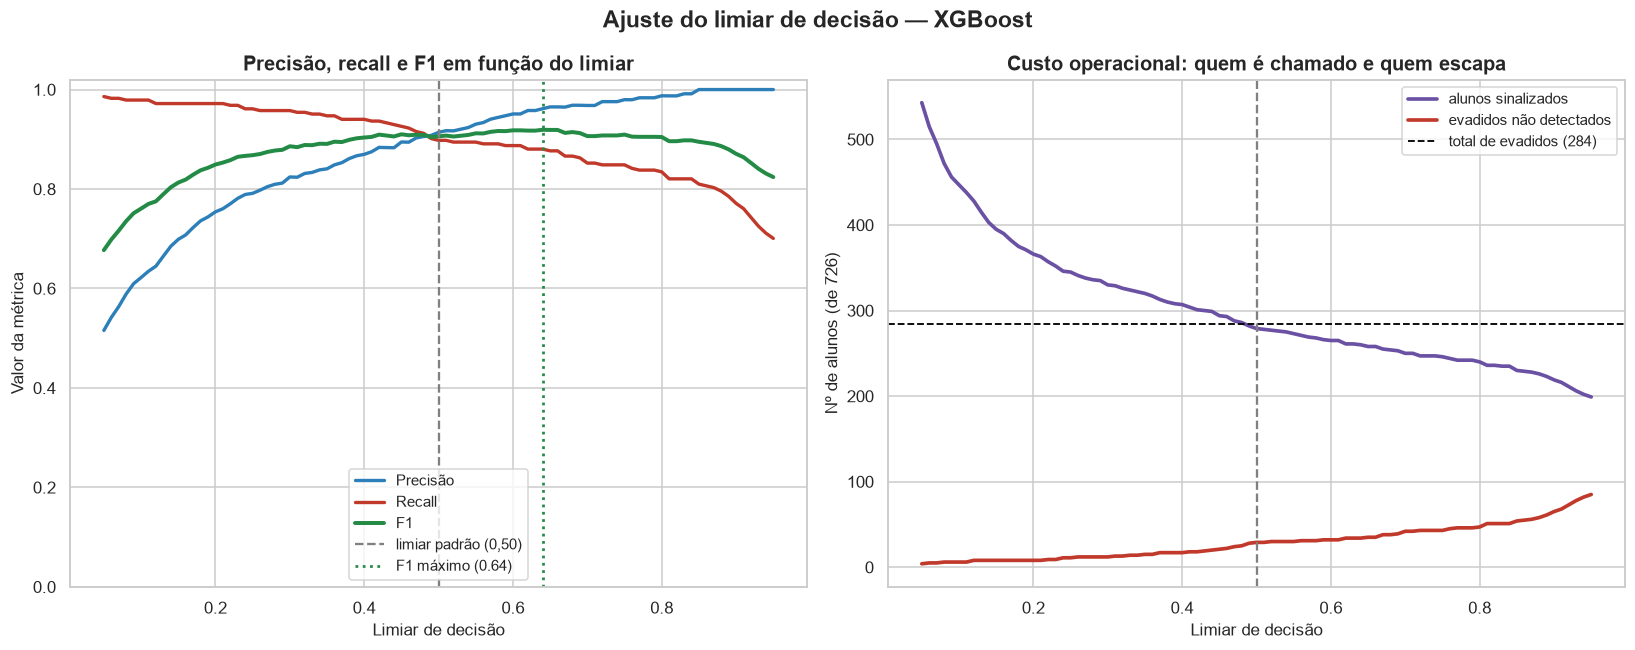

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

ax1.plot(curva["limiar"], curva["precisão"], label="Precisão", color="#2c7fb8", linewidth=2.2)
ax1.plot(curva["limiar"], curva["recall"], label="Recall", color="#c0392b", linewidth=2.2)
ax1.plot(curva["limiar"], curva["F1"], label="F1", color="#238b45", linewidth=2.6)
ax1.axvline(0.5, color="gray", linestyle="--", linewidth=1.5, label="limiar padrão (0,50)")
ax1.axvline(limiar_f1, color="#238b45", linestyle=":", linewidth=1.8,
            label=f"F1 máximo ({limiar_f1:.2f})")
ax1.set_xlabel("Limiar de decisão")
ax1.set_ylabel("Valor da métrica")
ax1.set_title("Precisão, recall e F1 em função do limiar")
ax1.legend(fontsize=9.5, loc="lower center")
ax1.set_ylim(0, 1.02)

ax2.plot(curva["limiar"], curva["sinalizados"], color="#6a51a3", linewidth=2.4,
         label="alunos sinalizados")
ax2.plot(curva["limiar"], (1 - curva["recall"]) * y_teste.sum(), color="#c0392b",
         linewidth=2.4, label="evadidos não detectados")
ax2.axhline(y_teste.sum(), color="black", linestyle="--", linewidth=1.2,
            label=f"total de evadidos ({int(y_teste.sum())})")
ax2.axvline(0.5, color="gray", linestyle="--", linewidth=1.5)
ax2.set_xlabel("Limiar de decisão")
ax2.set_ylabel("Nº de alunos (de 726)")
ax2.set_title("Custo operacional: quem é chamado e quem escapa")
ax2.legend(fontsize=9.5)

fig.suptitle(f"Ajuste do limiar de decisão — {MELHOR}", fontsize=15, fontweight="bold")
plt.tight_layout()
salvar("11_analise_limiar.png")
plt.show()

> ### Leitura — limiar de decisão
>
> O gráfico da direita é o mais útil para a conversa com a gestão, porque troca métricas abstratas
> por contagens de alunos. Ele mostra que existe uma faixa de limiares em que se ganha bastante
> recall a um custo modesto de falsos alarmes — e que, a partir de certo ponto, cada evadido
> adicional detectado passa a custar muitas convocações desnecessárias.
>
> **Decisão adotada neste trabalho:** o limiar padrão de 0,50 é mantido para todas as métricas
> reportadas, garantindo comparabilidade com a literatura. A análise fica registrada como
> **parâmetro de calibração institucional** — uma instituição com equipe de apoio ociosa deveria
> baixar o limiar; uma com equipe saturada, mantê-lo ou elevá-lo. Essa é uma decisão de política
> acadêmica, não de modelagem, e o trabalho entrega os números para que ela seja tomada com base em
> evidência.

## 10. Persistência do modelo

Salva-se o **pipeline completo** — SMOTE (inerte na predição) e modelo — não apenas o classificador.
Junto com o `preprocessador.joblib` do Notebook 2, isso permite reproduzir a predição para um aluno
novo a partir dos dados brutos, sem reconstruir nenhuma etapa manualmente.

In [29]:
caminho_melhor = os.path.join(DIR_MODELOS, "melhor_modelo.joblib")
joblib.dump(melhor_pipeline, caminho_melhor)
print(f"[salvo] {caminho_melhor}  ({MELHOR})")

# Os três modelos ficam guardados para eventual reanálise
import unicodedata

def slug_arquivo(texto):
    """Nome de arquivo ASCII, sem acentos nem espaços."""
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return texto.lower().replace(" ", "_")

for nome, pipeline in modelos_treinados.items():
    caminho = os.path.join(DIR_MODELOS, f"modelo_{slug_arquivo(nome)}.joblib")
    joblib.dump(pipeline, caminho)
    print(f"[salvo] {caminho}")

# Métricas em CSV para as tabelas da monografia
caminho_metricas = os.path.join(DIR_DADOS, "metricas_modelos.csv")
comparacao.to_csv(caminho_metricas, encoding="utf-8")
print(f"[salvo] {caminho_metricas}")

curva.to_csv(os.path.join(DIR_DADOS, "analise_limiar.csv"), index=False, encoding="utf-8")
print(f"[salvo] {os.path.join(DIR_DADOS, 'analise_limiar.csv')}")

# Informações para o Notebook 4
info_modelo = {
    "melhor_modelo": MELHOR,
    "arquivo": "melhor_modelo.joblib",
    "tipo_estimador": type(melhor_pipeline.named_steps["modelo"]).__name__,
    "hiperparametros": {
        k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
        for k, v in melhor_pipeline.named_steps["modelo"].get_params().items()
    },
    "metricas_teste": {k: float(v) for k, v in comparacao.loc[MELHOR, colunas_teste].items()},
    "limiar_padrao": 0.5,
    "limiar_f1_otimo": float(limiar_f1),
    "seed": SEED,
}
caminho_info = os.path.join(DIR_MODELOS, "info_melhor_modelo.json")
with open(caminho_info, "w", encoding="utf-8") as fh:
    json.dump(info_modelo, fh, ensure_ascii=False, indent=2)
print(f"[salvo] {caminho_info}")

[salvo] modelos\melhor_modelo.joblib  (XGBoost)
[salvo] modelos\modelo_regressao_logistica.joblib
[salvo] modelos\modelo_random_forest.joblib
[salvo] modelos\modelo_xgboost.joblib
[salvo] dados\metricas_modelos.csv
[salvo] dados\analise_limiar.csv
[salvo] modelos\info_melhor_modelo.json


In [30]:
# --- Conferência: o modelo recarregado reproduz as predições? ---------------
recarregado = joblib.load(caminho_melhor)
pred_recarregado = recarregado.predict(X_teste)

identico = bool((pred_recarregado == y_pred_melhor).all())
print(f"Predições do modelo recarregado idênticas: {identico}")
print(f"F1 conferido após recarga: {f1_score(y_teste, pred_recarregado):.4f}")
assert identico, "O modelo salvo não reproduz as predições — não prosseguir."
print("\nArtefato validado. Pronto para o Notebook 4.")

Predições do modelo recarregado idênticas: True
F1 conferido após recarga: 0.9059

Artefato validado. Pronto para o Notebook 4.


## 11. Síntese da Fase 4 do CRISP-DM

### Protocolo executado

| Item | Definição |
|---|---|
| Validação | `StratifiedKFold(5, shuffle=True, random_state=42)` |
| SMOTE | Dentro do `imblearn.Pipeline` — reaplicado por dobra, nunca na validação |
| Busca de hiperparâmetros | `GridSearchCV` exaustivo: 540 ajustes (RF) + 1.215 (XGBoost) |
| Métrica de decisão | F1 da classe `Dropout`; recall como desempate |
| Avaliação final | 726 alunos reais, 39,1% de evasão, sem dado sintético |

### O que os resultados dizem

1. **Os três modelos ficam próximos.** O ganho de F1 do XGBoost sobre a linha de base linear é de
   apenas **+1,4%**, e Random Forest e XGBoost empatam exatamente. O sinal está nos dados —
   desempenho acadêmico e situação financeira — e não na sofisticação do algoritmo.
2. **Todos superam largamente o piso trivial.** "Sempre Graduate" alcançaria 60,9% de acurácia com
   recall zero; os modelos entregam recall alto na classe que interessa.
3. **Não há indício de sobreajuste.** As métricas de teste são coerentes com as da validação cruzada,
   o que era esperado dado o controle de vazamento em todas as etapas.
4. **A interpretabilidade sai de graça.** Como o ganho de desempenho dos modelos complexos é pequeno,
   escolher o mais explicável não implica sacrificar qualidade preditiva — o que sustenta
   diretamente o objetivo do TCC.

### Limitações desta fase

- **Uma única partição de teste.** As métricas carregam incerteza amostral não quantificada. A
  validação cruzada mitiga isso no treino, mas o número final vem de uma partição só; validação
  cruzada aninhada ou *bootstrap* do teste seriam o próximo passo natural.
- **Comparação sem teste de significância.** As diferenças entre modelos não foram submetidas a
  teste estatístico (McNemar, por exemplo). Por isso o texto evita afirmar superioridade e trata os
  modelos como equivalentes na prática — leitura reforçada pelo empate exato entre Random Forest e
  XGBoost e pelo fato de o vencedor ter sido definido por um critério de desempate.
- **Métrica única para um problema de dois custos.** F1 combina precisão e recall em um número,
  assumindo implicitamente que os dois erros pesam igual — o que este trabalho afirma ser falso. A
  alternativa rigorosa seria uma métrica com custos assimétricos explícitos (F-beta com β > 1, ou
  perda esperada com custos monetários), o que exigiria da instituição uma estimativa do custo real
  de perder um aluno. A análise de limiar da seção 9 é o substituto pragmático adotado.
- **Variáveis do 2º semestre no modelo.** São as mais preditivas, mas só existem ao final do
  primeiro ano — o que restringe a aplicação prática a partir desse momento. Um modelo de
  alerta mais precoce, usando apenas dados de matrícula e do 1º semestre, é o trabalho futuro mais
  relevante para a utilidade institucional.

### Próximo passo

**Notebook 4 — Interpretabilidade com SHAP:** decompor as predições do modelo escolhido em
contribuições por variável, no nível global e individual, respondendo não apenas *quem* está em
risco, mas *por quê*.